<a href="https://colab.research.google.com/github/fenildhanani/Deep-Learning/blob/main/ANN2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [70]:
import numpy as np
import pandas as pd
import torch.optim as optim



In [71]:
df = pd.read_csv("powerplant_data.csv")

In [ ]:
df

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43
...,...,...,...,...,...
9563,15.12,48.92,1011.80,72.93,462.59
9564,33.41,77.95,1010.30,59.72,432.90
9565,15.99,43.34,1014.20,78.66,465.96
9566,17.65,59.87,1018.58,94.65,450.93


In [ ]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
df.shape

(9568, 5)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scled = scaler.fit_transform(X_train)
X_test_scled = scaler.transform(X_test)

In [ ]:
X_train_scled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]])

In [ ]:
import torch
import torch.nn as nn


X_train_tensor = torch.tensor(X_train_scled,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)


X_test_tensor = torch.tensor(X_test_scled,dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [ ]:
type(X_train_scled)

numpy.ndarray

In [ ]:
type(y_train)

pandas.core.series.Series

In [ ]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
# build Ann Model

class ANN(nn.Module):
  def __init__(self):
    super(ANN,self).__init__()

    self.model = nn.Sequential(
    nn.Linear(X_train.shape[1],6),
    nn.ReLU(),

    nn.Linear(6,6),
    nn.ReLU(),

      # output
    nn.Linear(6,1),



  )
  def forward(self, x):
      return self.model(x)

In [ ]:
model = ANN()

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# import torch.optim as optim

# model = ANN()

# # loss , potimizer
# crietrion = nn.MSELoss()
# optimizer = optim.Adam(model.parameters())

In [ ]:
train_losses = []
val_losses = []
epochs = 100
best_val_loss = float("inf")

for epoch in range(epochs):
  model.train()
  running_loss = 0.0



  for xb,yb in train_loader:
    optimizer.zero_grad()

    outputs = model(xb)
    loss = criterion(outputs, yb)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

  each_train_loss = running_loss / len(train_loader)
  train_losses.append(each_train_loss)
# validation
  model.eval()
  running_val_loss = 0.0

  with torch.no_grad():
    for xb,yb in test_loader:
      outputs = model(xb)
      loss = criterion(outputs, yb)
      running_val_loss += loss

  each_val_loss = running_val_loss / len(train_loader)
  val_losses.append(each_val_loss)

  print(f"epoch {epoch+1}/{epoch} ==> train loss ={each_train_loss}, eval_loss = {each_val_loss}")

  if each_val_loss < best_val_loss:
    best_val_loss = each_val_loss
    torch.save(model.state_dict(),"best_model.pt")

epoch 1/0 ==> train loss =206079.05403645834, eval_loss = 50963.87109375
epoch 2/1 ==> train loss =197868.5802734375, eval_loss = 47184.66015625
epoch 3/2 ==> train loss =174040.03430989583, eval_loss = 39098.1484375
epoch 4/3 ==> train loss =135154.85498046875, eval_loss = 28340.275390625
epoch 5/4 ==> train loss =92287.07620442708, eval_loss = 18407.57421875
epoch 6/5 ==> train loss =58496.83995768229, eval_loss = 11612.0595703125
epoch 7/6 ==> train loss =37481.85116373698, eval_loss = 7631.78125
epoch 8/7 ==> train loss =25282.062715657554, eval_loss = 5283.298828125
epoch 9/8 ==> train loss =18076.570576985676, eval_loss = 3883.026123046875
epoch 10/9 ==> train loss =13621.115983072918, eval_loss = 2952.20849609375
epoch 11/10 ==> train loss =10338.565767415364, eval_loss = 2194.302001953125
epoch 12/11 ==> train loss =7530.319671122233, eval_loss = 1542.0706787109375
epoch 13/12 ==> train loss =5214.951228841146, eval_loss = 1029.399169921875
epoch 14/13 ==> train loss =3466.5919

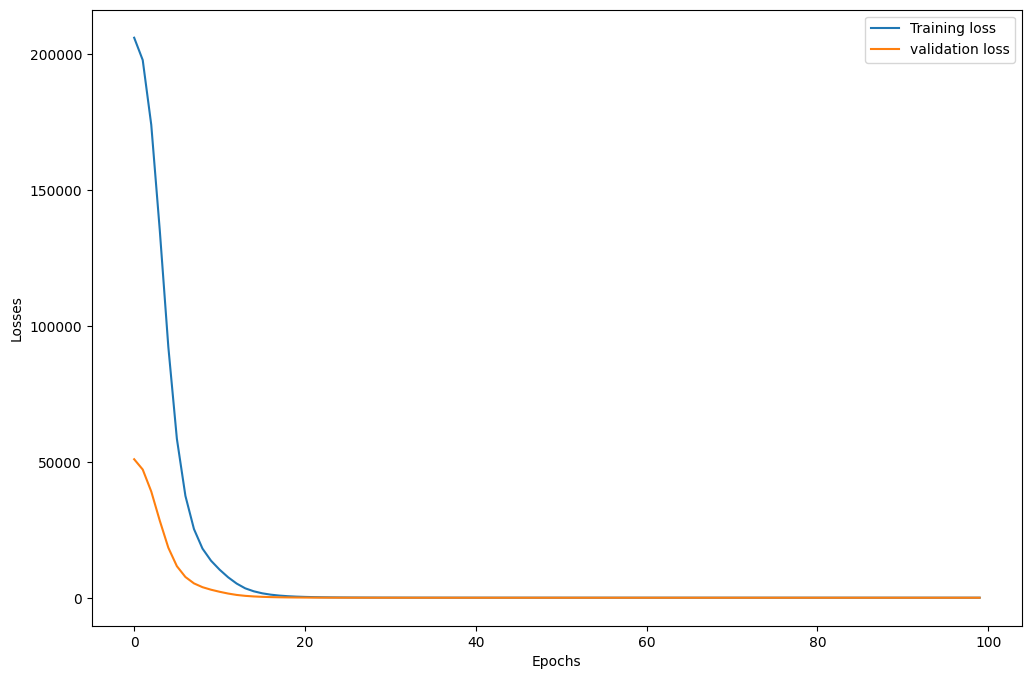

In [ ]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training loss": train_losses,
    "validation loss": val_losses
})

plt.figure(figsize = (12,8))
plt.plot(loss_df["Training loss"], label="Training loss")
plt.plot(loss_df["validation loss"], label="validation loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [ ]:
# Build our ANN model


In [ ]:
# loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [72]:
# Evaluate model
model.eval()
with torch.no_grad():
  train_preds = model(X_train_tensor)
  test_preds = model(X_test_tensor)

  train_mse_loss = criterion(train_preds,y_train_tensor)
  test_mse_loss = criterion(test_preds,y_test_tensor)
print("Traning MSE", train_mse_loss.item())
print("Testing MSE", test_mse_loss.item())

Traning MSE 20.547924041748047
Testing MSE 18.955476760864258


In [73]:
from sklearn.metrics import r2_score

print("R^2 score =", r2_score(y_test, test_preds))

R^2 score = 0.9337555066084515


In [74]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual value"])

pd.concat([predicted_df,actual_df],axis =1)

,Predicted values,Actual value
0,435.416840,433.27
1,436.725861,438.16
2,461.127289,458.42
3,475.964203,480.82
4,435.274933,441.41
...,...,...
1909,451.269196,456.70
1910,431.584778,438.04
1911,467.703247,467.80
1912,430.962952,437.14
